In [9]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [3]:
# Transform gambar menjadi Tensor
transform = transforms.ToTensor()

# Download dataset
train_dataset = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)

Training dataset: 60000
Testing dataset: 10000
Image shape: torch.Size([1, 28, 28])


In [11]:
from torch.utils.data import ConcatDataset, random_split

# Gabungkan dataset training dan testing
full_dataset = ConcatDataset([
    train_dataset,
    test_dataset
])

# Hitung jumlah data
total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

# Fixed seed agar pembagian selalu konsisten
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator
)

print("Total dataset:", total_size)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Total dataset: 70000
Training: 56000
Validation: 7000
Testing: 7000


In [12]:
from torch.utils.data import DataLoader

# Batch size
BATCH_SIZE = 128

# DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 438
Validation batches: 55
Testing batches: 55


In [13]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image range:", images.min().item(), "-", images.max().item())

Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Image range: 0.0 - 1.0


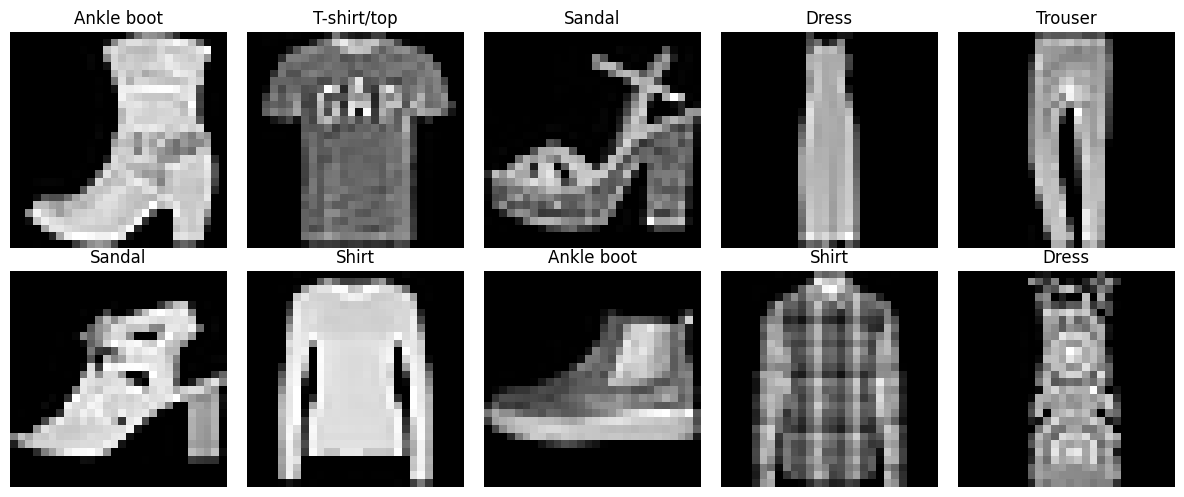

In [14]:
# Nama kelas Fashion-MNIST
classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Ambil satu batch gambar
images, labels = next(iter(train_loader))

# Visualisasi 10 gambar pertama
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(classes[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()